In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage

sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'Segoe UI'
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.figsize'] = (10, 5)

data_dir = r"D:\Tài Liệu\Đồ án TH_KTDL\Data"
data_path = os.path.join(data_dir, "telco_scaled.csv")

df_scaled = pd.read_csv(data_path)

churn_labels = df_scaled['roi_bo'].values if 'roi_bo' in df_scaled.columns else None
ignore_cols = ['ma_khach_hang', 'roi_bo']
feature_cols = [c for c in df_scaled.columns if c not in ignore_cols]


X = df_scaled[feature_cols].values

print(f"-> Nạp dữ liệu thành công từ: {data_path}")
print(f"-> Kích thước ma trận gom cụm: {X.shape[0]} khách hàng x {X.shape[1]} đặc trưng.")

-> Nạp dữ liệu thành công từ: D:\Tài Liệu\Đồ án TH_KTDL\Data\telco_scaled.csv
-> Kích thước ma trận gom cụm: 7032 khách hàng x 14 đặc trưng.


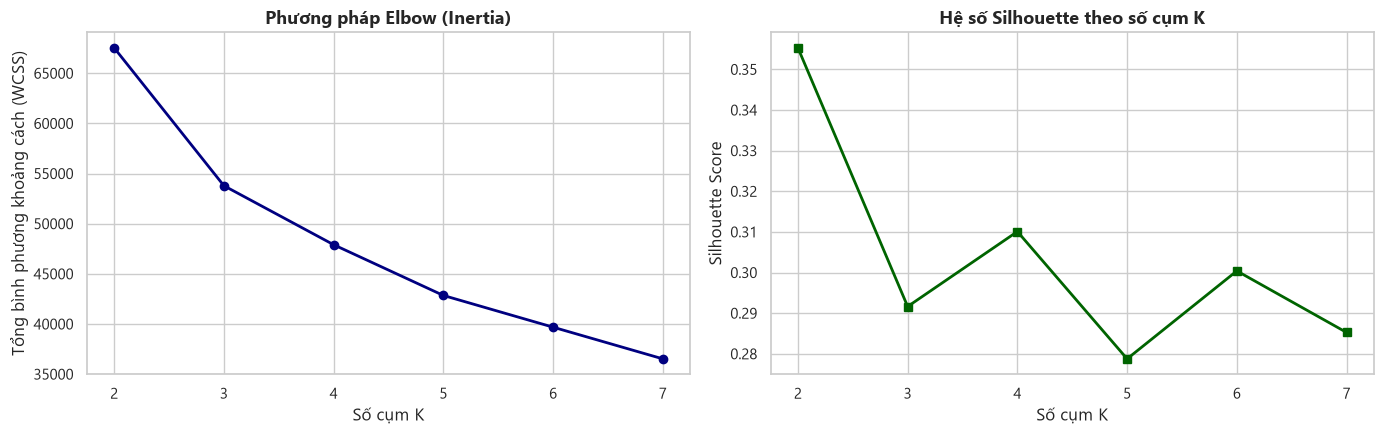

-> K-Means hoàn thành huấn luyện với K = 4


In [2]:
#Thuật toán K - Means, chọn K tối ưu
k_range = range(2, 8)
inertia = []
sil_km = []

for k in k_range:
    km = KMeans(n_clusters=k, init="k-means++", random_state=42, n_init=10)
    labels = km.fit_predict(X)
    inertia.append(km.inertia_)
    sil_km.append(silhouette_score(X, labels))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

# Đồ thị Elbow
ax[0].plot(k_range, inertia, marker='o', color='navy', linewidth=2)
ax[0].set_title("Phương pháp Elbow (Inertia)", fontsize=13, fontweight='bold')
ax[0].set_xlabel("Số cụm K")
ax[0].set_ylabel("Tổng bình phương khoảng cách (WCSS)")

# Đồ thị Silhouette Score
ax[1].plot(k_range, sil_km, marker='s', color='darkgreen', linewidth=2)
ax[1].set_title("Hệ số Silhouette theo số cụm K", fontsize=13, fontweight='bold')
ax[1].set_xlabel("Số cụm K")
ax[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

# Chọn K = 4 (cân bằng giữa cấu trúc cụm và ý nghĩa phân khúc nghiệp vụ)
k_opt = 4
kmeans_final = KMeans(n_clusters=k_opt, init="k-means++", random_state=42, n_init=10)
labels_km = kmeans_final.fit_predict(X)

print(f"-> K-Means hoàn thành huấn luyện với K = {k_opt}")

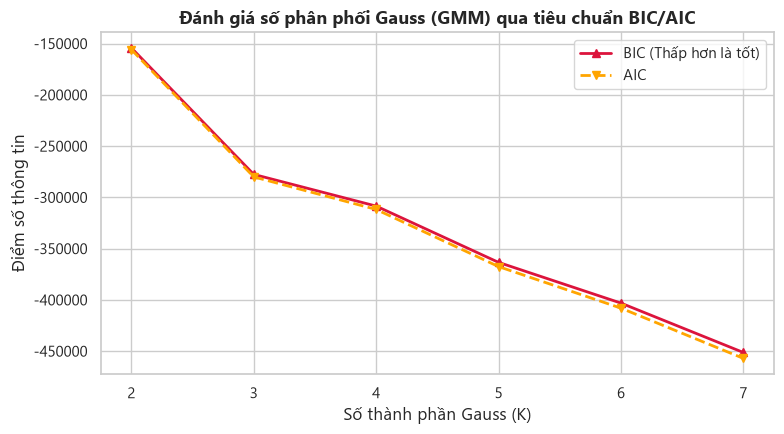

-> GMM hoàn thành huấn luyện với K = 4


In [3]:
#Thuật toán GMM
bic_scores = []
aic_scores = []

for k in k_range:
    gmm = GaussianMixture(n_components=k, covariance_type="full", random_state=42)
    gmm.fit(X)
    bic_scores.append(gmm.bic(X))
    aic_scores.append(gmm.aic(X))

plt.figure(figsize=(8, 4.5))
plt.plot(k_range, bic_scores, marker='^', color='crimson', label='BIC (Thấp hơn là tốt)', linewidth=2)
plt.plot(k_range, aic_scores, marker='v', color='orange', label='AIC', linestyle='--', linewidth=2)
plt.title("Đánh giá số phân phối Gauss (GMM) qua tiêu chuẩn BIC/AIC", fontsize=13, fontweight='bold')
plt.xlabel("Số thành phần Gauss (K)")
plt.ylabel("Điểm số thông tin")
plt.legend()
plt.tight_layout()
plt.show()

# Huấn luyện GMM với K_opt
gmm_final = GaussianMixture(n_components=k_opt, covariance_type="full", random_state=42)
labels_gmm = gmm_final.fit_predict(X)

print(f"-> GMM hoàn thành huấn luyện với K = {k_opt}")

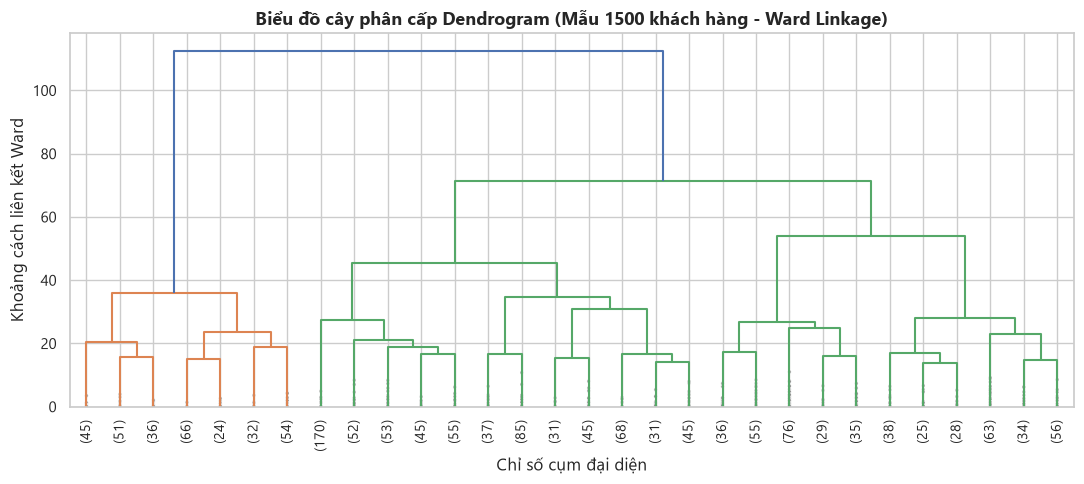

-> Hierarchical Clustering hoàn thành huấn luyện với K = 4


In [4]:
#Thuật toán Hierarchical Clustering
# Lấy mẫu ngẫu nhiên 1.500 bản ghi để vẽ Dendrogram tránh tràn RAM và nghẽn đồ họa
np.random.seed(42)
sample_size = min(1500, X.shape[0])
sample_idx = np.random.choice(X.shape[0], size=sample_size, replace=False)
X_sample = X[sample_idx]

# Tính ma trận liên kết Linkage theo Ward
linked = linkage(X_sample, method='ward')

plt.figure(figsize=(11, 5))
dendrogram(linked, truncate_mode='lastp', p=30, leaf_rotation=90., leaf_font_size=10., show_contracted=True)
plt.title(f"Biểu đồ cây phân cấp Dendrogram (Mẫu {sample_size} khách hàng - Ward Linkage)", fontsize=13, fontweight='bold')
plt.xlabel("Chỉ số cụm đại diện")
plt.ylabel("Khoảng cách liên kết Ward")
plt.tight_layout()
plt.show()

# Huấn luyện mô hình Agglomerative trên toàn bộ dữ liệu
hierarchical_final = AgglomerativeClustering(n_clusters=k_opt, linkage='ward')
labels_hierarchical = hierarchical_final.fit_predict(X)

print(f"-> Hierarchical Clustering hoàn thành huấn luyện với K = {k_opt}")

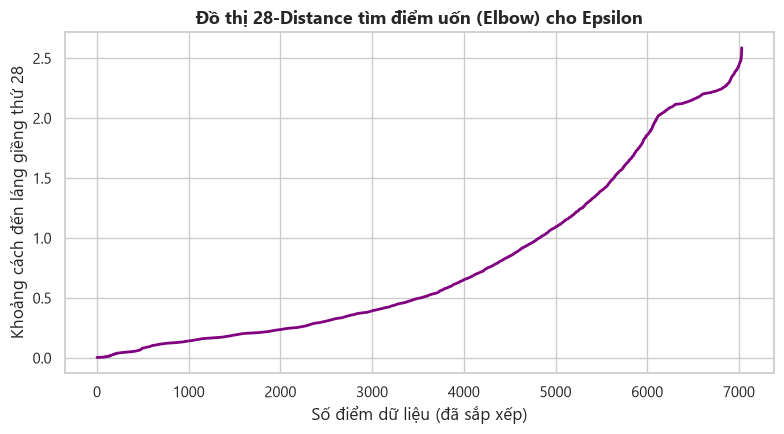

-> DBSCAN hoàn thành: Phát hiện 2 cụm hợp lệ và 0 điểm nhiễu (0.0%).


In [5]:
# Xác định tham số MinPts = 2 * số đặc trưng
min_pts = 2 * X.shape[1]

# Tính khoảng cách đến láng giềng thứ MinPts
neighbors = NearestNeighbors(n_neighbors=min_pts)
neighbors.fit(X)
distances, _ = neighbors.kneighbors(X)

# Sắp xếp khoảng cách tăng dần
sorted_distances = np.sort(distances[:, min_pts - 1])

plt.figure(figsize=(8, 4.5))
plt.plot(sorted_distances, color='purple', linewidth=2)
plt.title(f"Đồ thị {min_pts}-Distance tìm điểm uốn (Elbow) cho Epsilon", fontsize=13, fontweight='bold')
plt.xlabel("Số điểm dữ liệu (đã sắp xếp)")
plt.ylabel(f"Khoảng cách đến láng giềng thứ {min_pts}")
plt.grid(True)
plt.tight_layout()
plt.show()

# Chạy DBSCAN (Chọn ngưỡng eps quanh điểm bắt đầu dốc đứng của đường cong)
eps_val = 2.5
dbscan_final = DBSCAN(eps=eps_val, min_samples=min_pts)
labels_dbscan = dbscan_final.fit_predict(X)

n_clusters_db = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_noise = list(labels_dbscan).count(-1)
noise_ratio = round((n_noise / len(labels_dbscan)) * 100, 2)

print(f"-> DBSCAN hoàn thành: Phát hiện {n_clusters_db} cụm hợp lệ và {n_noise} điểm nhiễu ({noise_ratio}%).")


BẢNG SO SÁNH HIỆU NĂNG 4 THUẬT TOÁN GOM CỤM


,Thuật toán,Số cụm,Silhouette (↑),Davies-Bouldin (↓),Calinski-Harabasz (↑)
0,K-Means,4,0.3101,1.4711,2471.65
1,GMM,4,0.3075,1.4797,2417.64
2,Hierarchical,4,0.3075,1.4797,2417.64
3,DBSCAN (eps=2.5),2,0.3553,1.1093,3218.61


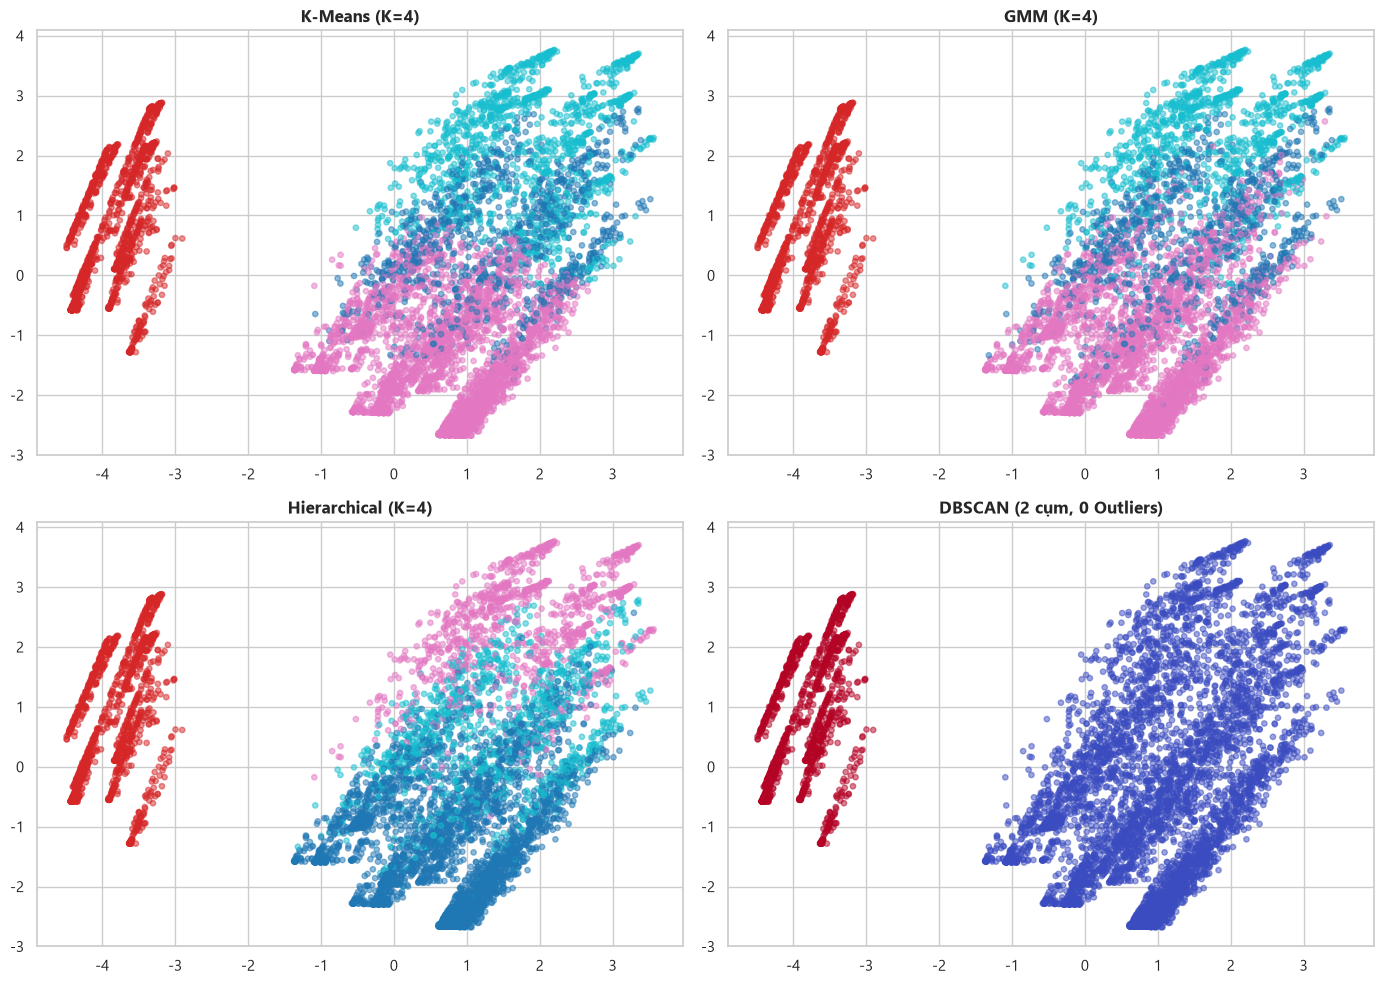


-> Đã lưu mô hình tối ưu vào file: 'best_model.pkl' để sẵn sàng cho phần Web Streamlit!


In [6]:
# 1. Hàm tính toán 3 chỉ số đánh giá nội tại
def evaluate_clustering(labels, name):
    valid_mask = labels != -1
    v_data = X[valid_mask]
    v_labels = labels[valid_mask]
    
    if len(set(v_labels)) < 2:
        return {"Thuật toán": name, "Số cụm": len(set(v_labels)), "Silhouette (↑)": None, "Davies-Bouldin (↓)": None, "Calinski-Harabasz (↑)": None}
    
    return {
        "Thuật toán": name,
        "Số cụm": len(set(v_labels)),
        "Silhouette (↑)": round(silhouette_score(v_data, v_labels), 4),
        "Davies-Bouldin (↓)": round(davies_bouldin_score(v_data, v_labels), 4),
        "Calinski-Harabasz (↑)": round(calinski_harabasz_score(v_data, v_labels), 2)
    }

# Tổng hợp bảng đối chuẩn
results = [
    evaluate_clustering(labels_km, "K-Means"),
    evaluate_clustering(labels_gmm, "GMM"),
    evaluate_clustering(labels_hierarchical, "Hierarchical"),
    evaluate_clustering(labels_dbscan, f"DBSCAN (eps={eps_val})")
]

df_summary = pd.DataFrame(results)
print("\n" + "="*70)
print("BẢNG SO SÁNH HIỆU NĂNG 4 THUẬT TOÁN GOM CỤM")
print("="*70)
display(df_summary)

# 2. Chiếu dữ liệu xuống không gian 2D bằng PCA để vẽ biểu đồ trực quan
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].scatter(X_pca[:, 0], X_pca[:, 1], c=labels_km, cmap='tab10', alpha=0.5, s=15)
axes[0, 0].set_title(f"K-Means (K={k_opt})", fontweight='bold')

axes[0, 1].scatter(X_pca[:, 0], X_pca[:, 1], c=labels_gmm, cmap='tab10', alpha=0.5, s=15)
axes[0, 1].set_title(f"GMM (K={k_opt})", fontweight='bold')

axes[1, 0].scatter(X_pca[:, 0], X_pca[:, 1], c=labels_hierarchical, cmap='tab10', alpha=0.5, s=15)
axes[1, 0].set_title(f"Hierarchical (K={k_opt})", fontweight='bold')

# Điểm nhiễu trong DBSCAN gắn nhãn -1 vẽ màu xám mờ
scatter_db = axes[1, 1].scatter(X_pca[:, 0], X_pca[:, 1], c=labels_dbscan, cmap='coolwarm', alpha=0.5, s=15)
axes[1, 1].set_title(f"DBSCAN ({n_clusters_db} cụm, {n_noise} Outliers)", fontweight='bold')

plt.tight_layout()
plt.show()

# 3. Đóng gói mô hình K-Means làm mô hình phục vụ Web Demo
joblib.dump(kmeans_final, "best_model.pkl")
print("\n-> Đã lưu mô hình tối ưu vào file: 'best_model.pkl' để sẵn sàng cho phần Web Streamlit!")